In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR))



In [5]:
from src.data.validation import build_manifest

DATASET_DIR = Path("../data/raw/classification").resolve()

manifest = build_manifest(DATASET_DIR)

OUTPUT_PATH = Path("../artifacts/classification/manifest.csv")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

manifest.to_csv(OUTPUT_PATH, index=False)


In [6]:
from src.data.splitting import split_dataset , export_classification_splits

train_df, val_df, test_df = split_dataset(manifest)


In [7]:

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}: {len(df)} images")
    print(df["label"].value_counts().sort_index())


Train: 4916 images
label
glioma        1135
meningioma    1151
notumor       1400
pituitary     1230
Name: count, dtype: int64

Validation: 1053 images
label
glioma        243
meningioma    247
notumor       300
pituitary     263
Name: count, dtype: int64

Test: 1054 images
label
glioma        243
meningioma    247
notumor       300
pituitary     264
Name: count, dtype: int64


In [ ]:
split = {
    "train" : train_df,
    "valid":val_df,
    "test":test_df
}

export_classification_splits(splits=split,output_dir="../data/processed/classification",
)

In [9]:
from src.classification.dataset import load_classification_image

train_ds, val_ds, test_ds, class_names = (
    load_classification_image(data_dir="../data/processed/classification/")
)

print("Classes :", class_names)

for images, labels in train_ds.take(1):
    print("Dimensions des images :", images.shape)
    print("Dimensions des labels :", labels.shape)
    print("Type des images :", images.dtype)

Found 4916 files belonging to 4 classes.
Found 1053 files belonging to 4 classes.
Found 1054 files belonging to 4 classes.
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Dimensions des images : (32, 224, 224, 3)
Dimensions des labels : (32,)
Type des images : <dtype: 'float32'>


In [10]:
from src.classification.pepline  import (
    prepare_train,
    prepare_evaluation,
)

import tensorflow as tf

In [11]:
train_ds = train_ds.map(
    prepare_train,
    num_parallel_calls=tf.data.AUTOTUNE,
)

val_ds = val_ds.map(
    prepare_evaluation,
    num_parallel_calls=tf.data.AUTOTUNE,
)

test_ds = test_ds.map(
    prepare_evaluation,
    num_parallel_calls=tf.data.AUTOTUNE,
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

In [ ]:
from src.classification.model import build_googlenet

model = build_googlenet(
    num_classes=4,
    trainable_base=True,
    learning_rate=1e-5,
)

model.summary()

In [ ]:
from src.classification.train import train_googlenet

model, history = train_googlenet(
    model=model,
    train_ds=train_ds,
    valid_ds=val_ds,
    epochs=30,
    output_dir="artifacts/models",
    patience=5,
)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Époque")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Époque")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import tf_keras as keras
import tensorflow_hub as hub

model_path = "artifacts/models/googlenet_best.keras"

model = keras.models.load_model(
    model_path,
    custom_objects={
        "KerasLayer": hub.KerasLayer
    },
    compile=False
)

print("Modèle GoogLeNet chargé avec succès !")
model.summary()


ÉVALUATION GOOGLENET : TEST
Nombre d'images : 1054
Accuracy        : 0.8567
Precision macro : 0.8714
Recall macro    : 0.8480
F1-score macro  : 0.8501

Métriques pondérées :
Precision : 0.8726
Recall    : 0.8567
F1-score  : 0.8557

Rapport de classification :
              precision    recall  f1-score   support

      glioma     0.9939    0.6708    0.8010       243
  meningioma     0.6907    0.8138    0.7472       247
     notumor     0.8939    0.9833    0.9365       300
   pituitary     0.9071    0.9242    0.9156       264

    accuracy                         0.8567      1054
   macro avg     0.8714    0.8480    0.8501      1054
weighted avg     0.8726    0.8567    0.8557      1054



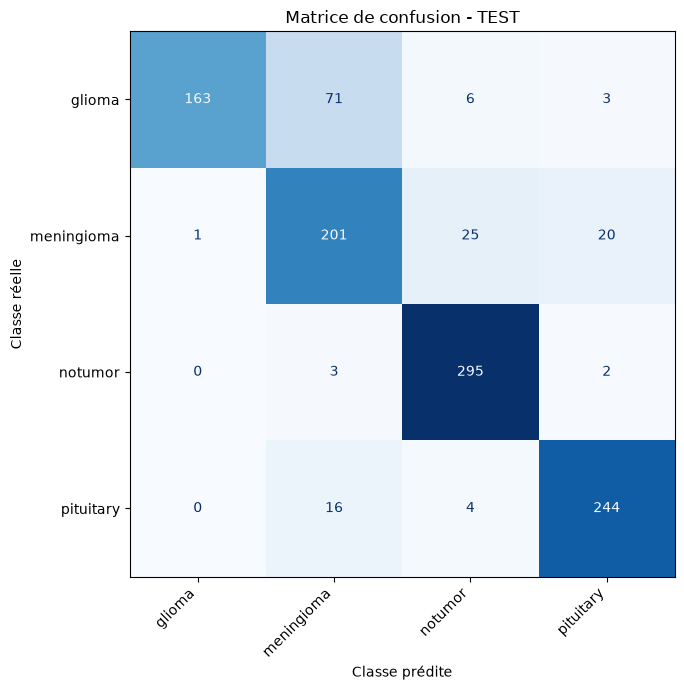


Matrice sauvegardée : artifacts\evaluation\confusion_matrix_test.png
Rapport sauvegardé : artifacts\evaluation\classification_report_test.txt

ÉVALUATION GOOGLENET : TRAIN
Nombre d'images : 4916
Accuracy        : 0.9223
Precision macro : 0.9210
Recall macro    : 0.9184
F1-score macro  : 0.9170

Métriques pondérées :
Precision : 0.9246
Recall    : 0.9223
F1-score  : 0.9209

Rapport de classification :
              precision    recall  f1-score   support

      glioma     0.8403    0.9551    0.8940      1135
  meningioma     0.9197    0.7663    0.8360      1151
     notumor     0.9800    0.9821    0.9811      1400
   pituitary     0.9438    0.9699    0.9567      1230

    accuracy                         0.9223      4916
   macro avg     0.9210    0.9184    0.9170      4916
weighted avg     0.9246    0.9223    0.9209      4916



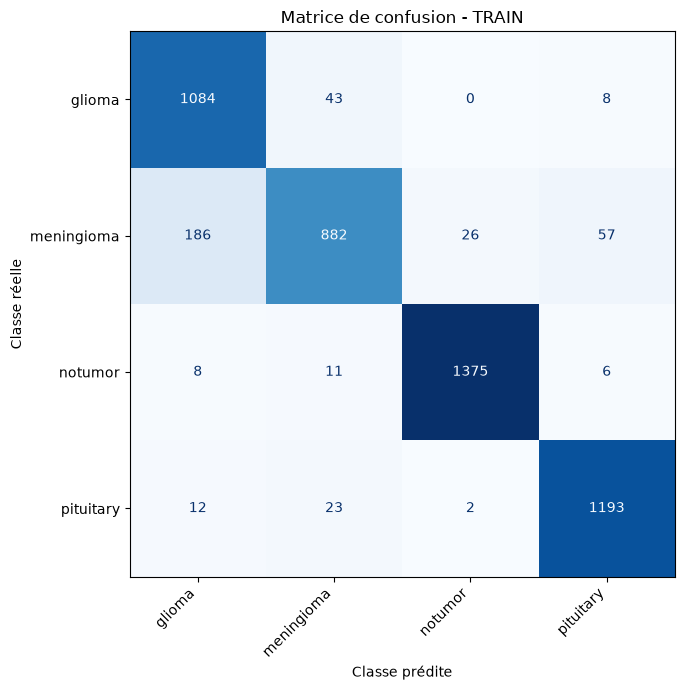


Matrice sauvegardée : artifacts\evaluation\confusion_matrix_train.png
Rapport sauvegardé : artifacts\evaluation\classification_report_train.txt


In [16]:
from src.classification.evaluate import evaluate_googlenet

test_results = evaluate_googlenet(
    model=model,
    dataset=test_ds,
    class_names=class_names,
    dataset_name="TEST",
    output_dir="artifacts/evaluation",
)

train_results = evaluate_googlenet(
    model=model,
    dataset=train_ds,
    class_names=class_names,
    dataset_name="TRAIN",
    output_dir="artifacts/evaluation",
)



In [17]:
import tensorflow_hub as hub
import kagglehub

model_path = kagglehub.model_download(
    "google/inception-v1/tensorFlow2/feature-vector/1"
)

base_model = hub.KerasLayer(
    model_path,
    trainable=True,
    name="googlenet_backbone"
)

print("Variables entraînables :", len(base_model.trainable_weights))

print(
    "Paramètres entraînables :",
    sum(w.shape.num_elements() for w in base_model.trainable_weights)
)

c:\Users\errak\Desktop\BrainTumorDetectionAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Variables entraînables : 114
Paramètres entraînables : 5592624


In [15]:
import pandas as pd

metrics_df = pd.DataFrame([
    {
        "Dataset": "Train",
        "Accuracy": train_results["accuracy"],
        "Precision (macro)": train_results["precision_macro"],
        "Recall (macro)": train_results["recall_macro"],
        "F1-score (macro)": train_results["f1_macro"],
    },
    {
        "Dataset": "Test",
        "Accuracy": test_results["accuracy"],
        "Precision (macro)": test_results["precision_macro"],
        "Recall (macro)": test_results["recall_macro"],
        "F1-score (macro)": test_results["f1_macro"],
    },
])

metrics_df.round(4)

,Dataset,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Train,0.9231,0.9217,0.919,0.9177
1,Test,0.8567,0.8714,0.848,0.8501
